<a href="https://colab.research.google.com/github/TOUATI-MOHAMED/DeepVision-Masterclass/blob/main/Computer_Vision_Masterclass_Deep_dream.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision Masterclass: Deep Dream

## Importing the libraries

- Adapted from: https://www.tensorflow.org/beta/tutorials/generative/deepdream

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
tf.__version__

'2.4.1'

## Loading the pre-built convolutional neural network

- InceptionNet: https://www.tensorflow.org/api_docs/python/tf/keras/applications/inception_v3
- Original paper: https://www.cv-foundation.org/openaccess/content_cvpr_2016/papers/Szegedy_Rethinking_the_Inception_CVPR_2016_paper.pdf
- Imagenet: http://www.image-net.org/

In [ ]:
base_model = tf.keras.applications.InceptionV3(include_top=False, weights='imagenet')

87916544/87910968 [==============================] - 0s 0us/step


In [ ]:
base_model.summary()

Model: "inception_v3"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, None, None,  0                                            
__________________________________________________________________________________________________
conv2d (Conv2D)                 (None, None, None, 3 864         input_1[0][0]                    
__________________________________________________________________________________________________
batch_normalization (BatchNorma (None, None, None, 3 96          conv2d[0][0]                     
__________________________________________________________________________________________________
activation (Activation)         (None, None, None, 3 0           batch_normalization[0][0]        
_______________________________________________________________________________________

In [ ]:
len(base_model.layers)

311

In [ ]:
# Relu
#names = ['mixed3', 'mixed5', 'mixed8', 'mixed9']
names = ['mixed3', 'mixed5']

In [ ]:
base_model.input

<KerasTensor: shape=(None, None, None, 3) dtype=float32 (created by layer 'input_1')>

In [ ]:
layers = [base_model.get_layer(name).output for name in names]

In [ ]:
layers

[<KerasTensor: shape=(None, None, None, 768) dtype=float32 (created by layer 'mixed3')>,
 <KerasTensor: shape=(None, None, None, 768) dtype=float32 (created by layer 'mixed5')>]

In [ ]:
deep_dream_model = tf.keras.Model(inputs = base_model.input, outputs = layers)

## Loading and pre-processing the image

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
image = tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/Computer Vision Masterclass/Images/StaryNight.jpg',
                                              target_size=(225, 375))

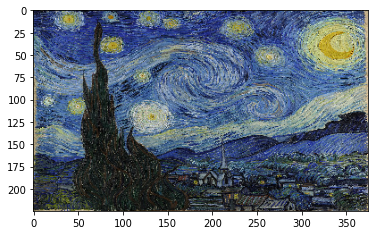

In [ ]:
plt.imshow(image);

In [ ]:
type(image)

PIL.Image.Image

In [ ]:
image.size

(375, 225)

In [ ]:
image.mode, len(image.mode)

('RGB', 3)

In [ ]:
list(image.getdata())

[(6, 10, 11),
 (29, 33, 68),
 (35, 46, 66),
 (38, 46, 65),
 (46, 49, 68),
 (23, 29, 29),
 (13, 16, 31),
 (57, 62, 84),
 (85, 87, 99),
 (147, 146, 142),
 (141, 136, 130),
 (108, 118, 117),
 (16, 22, 58),
 (19, 29, 64),
 (82, 97, 120),
 (79, 94, 125),
 (147, 150, 169),
 (28, 31, 76),
 (57, 62, 104),
 (13, 20, 39),
 (37, 38, 68),
 (21, 30, 61),
 (4, 11, 53),
 (25, 32, 74),
 (48, 50, 99),
 (134, 132, 182),
 (127, 131, 156),
 (126, 133, 159),
 (138, 151, 170),
 (64, 76, 124),
 (67, 82, 123),
 (60, 75, 114),
 (75, 90, 133),
 (84, 119, 141),
 (52, 83, 78),
 (137, 156, 128),
 (51, 66, 71),
 (149, 170, 199),
 (153, 176, 220),
 (53, 81, 128),
 (90, 117, 170),
 (68, 94, 127),
 (161, 175, 175),
 (142, 155, 190),
 (92, 118, 133),
 (50, 72, 129),
 (107, 133, 158),
 (99, 122, 153),
 (27, 36, 67),
 (34, 45, 77),
 (95, 116, 133),
 (21, 41, 66),
 (52, 59, 103),
 (50, 55, 110),
 (34, 39, 69),
 (22, 24, 49),
 (3, 2, 33),
 (4, 7, 26),
 (28, 37, 36),
 (19, 27, 30),
 (19, 24, 44),
 (43, 48, 78),
 (93, 104, 1

In [ ]:
image = tf.keras.preprocessing.image.img_to_array(image)

In [ ]:
type(image)

numpy.ndarray

In [ ]:
image.shape

(225, 375, 3)

In [ ]:
image.min(), image.max()

(0.0, 255.0)

In [ ]:
# image = image / 255
image = tf.keras.applications.inception_v3.preprocess_input(image)

In [ ]:
image.min(), image.max()

(-1.0, 1.0)

## Getting the activations

In [ ]:
image.shape

(225, 375, 3)

In [ ]:
image_batch = tf.expand_dims(image, axis = 0)

In [ ]:
image_batch.shape

TensorShape([1, 225, 375, 3])

In [ ]:
activations = deep_dream_model.predict(image_batch)

In [ ]:
deep_dream_model.outputs

[<KerasTensor: shape=(None, None, None, 768) dtype=float32 (created by layer 'mixed3')>,
 <KerasTensor: shape=(None, None, None, 768) dtype=float32 (created by layer 'mixed5')>]

In [ ]:
len(activations)

2

In [ ]:
activations[1]

array([[[[0.        , 0.        , 1.469636  , ..., 0.        ,
          0.        , 0.        ],
         [2.4891303 , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         [1.0993059 , 0.        , 0.35030425, ..., 0.        ,
          0.        , 0.        ],
         ...,
         [0.        , 0.        , 0.2563457 , ..., 1.210185  ,
          0.        , 0.        ],
         [0.        , 0.16377343, 0.6175297 , ..., 0.8696385 ,
          0.        , 0.        ],
         [0.13447075, 0.        , 1.6310176 , ..., 0.5379394 ,
          0.        , 0.        ]],

        [[0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         [0.        , 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         [0.57730883, 0.        , 0.        , ..., 0.        ,
          0.        , 0.        ],
         ...,
         [0.        , 0.        , 0.        , ..., 1.2298602 ,
          0.        , 0.0

In [ ]:
activations[0].shape, activations[1].shape

((1, 12, 21, 768), (1, 12, 21, 768))

## Calculating the loss

In [ ]:
def calculate_loss(image, network):
  image_batch = tf.expand_dims(image, axis = 0)
  activations = network(image_batch)

  losses = []
  for act in activations:
    loss = tf.math.reduce_mean(act)
    losses.append(loss)

  #print(losses)
  #print(np.shape(losses))
  #print(tf.reduce_sum(losses))

  return tf.reduce_sum(losses)

In [ ]:
0.45195404 + 0.16485049

0.61680453

In [ ]:
loss = calculate_loss(image, deep_dream_model)
loss

<tf.Tensor: shape=(), dtype=float32, numpy=0.61680454>

## Gradient ascent

In [ ]:
@tf.function
def deep_dream(network, image, learning_rate):
  with tf.GradientTape() as tape:
    tape.watch(image)
    loss = calculate_loss(image, network)

  gradients = tape.gradient(loss, image) # Derivate
  gradients /= tf.math.reduce_std(gradients)
  image = image + gradients * learning_rate
  image = tf.clip_by_value(image, -1, 1)

  return loss, image

In [ ]:
def inverse_transform(image):
  image = 255 * (image + 1.0) / 2.0
  return tf.cast(image, tf.uint8)

In [ ]:
def run_deep_dream(network, image, epochs, learning_rate):
  for epoch in range(epochs):
    loss, image = deep_dream(network, image, learning_rate)

    if epoch % 200 == 0:
      plt.figure(figsize=(12,12))
      plt.imshow(inverse_transform(image))
      plt.show()
      print('Epoch {}, loss {}'.format(epoch, loss))

## Generating images

In [ ]:
image.shape, type(image)

((225, 375, 3), numpy.ndarray)

In [ ]:
run_deep_dream(network=deep_dream_model, image=image, epochs = 8000, learning_rate=0.0001)

## Homework

In [ ]:
image = tf.keras.preprocessing.image.load_img('/content/drive/MyDrive/Computer Vision Masterclass/Images/sky.jpeg',
                                              target_size = (225, 375))

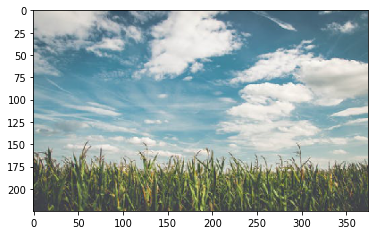

In [ ]:
plt.imshow(image);

In [ ]:
image = tf.keras.preprocessing.image.img_to_array(image)
image = tf.keras.applications.inception_v3.preprocess_input(image)

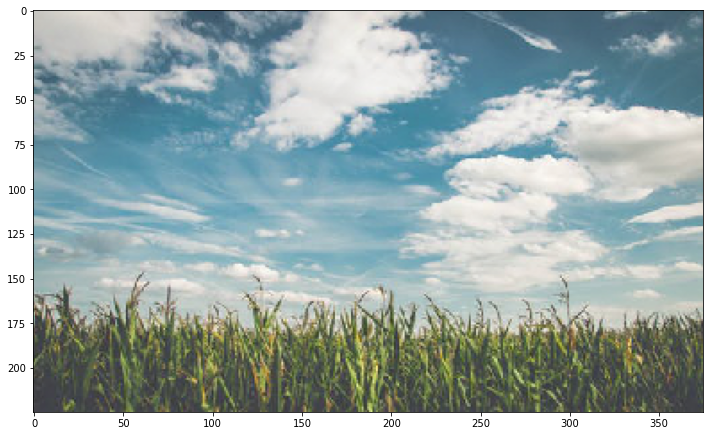

Epoch 0, loss 0.6144235134124756


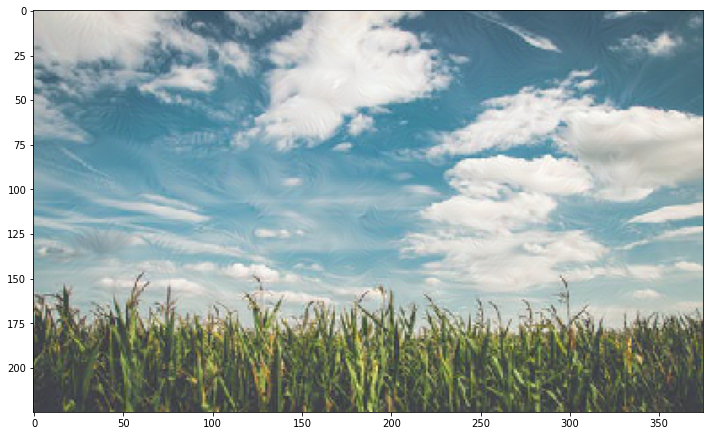

Epoch 200, loss 0.9559670686721802


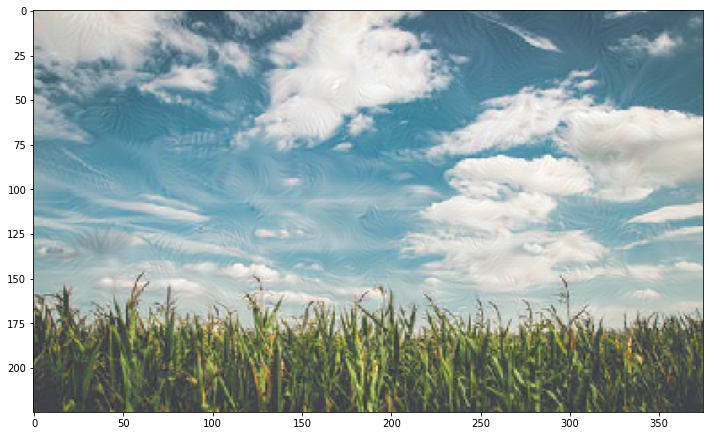

Epoch 400, loss 1.1461961269378662


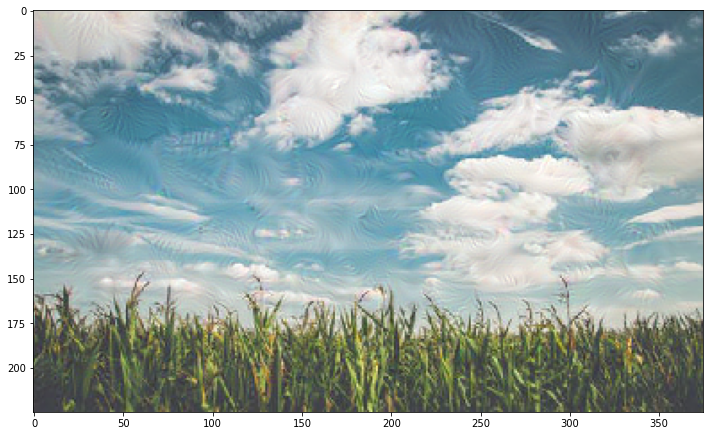

Epoch 600, loss 1.2786353826522827


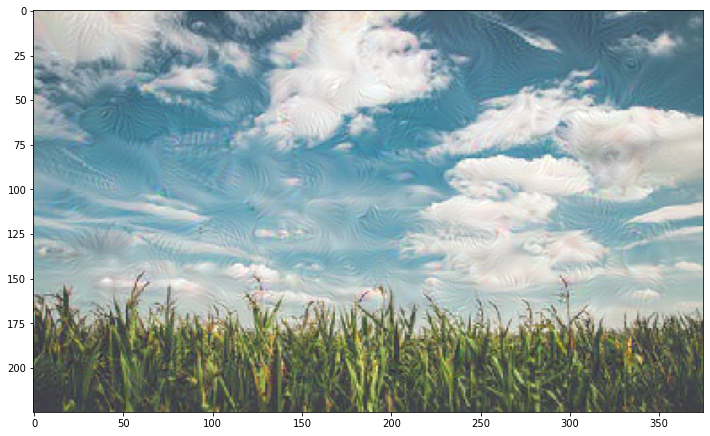

Epoch 800, loss 1.378812313079834


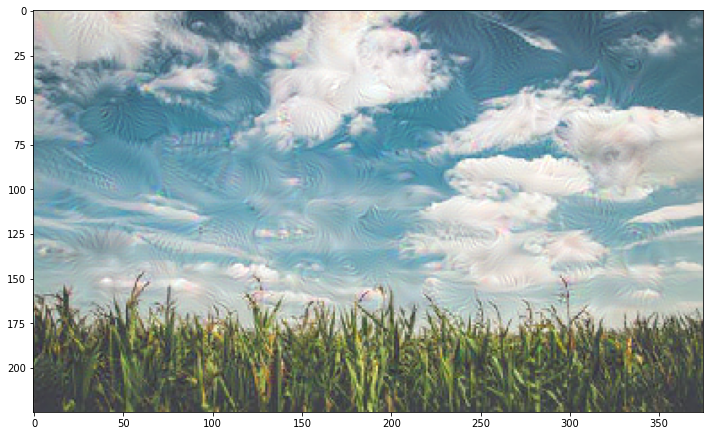

Epoch 1000, loss 1.4574533700942993


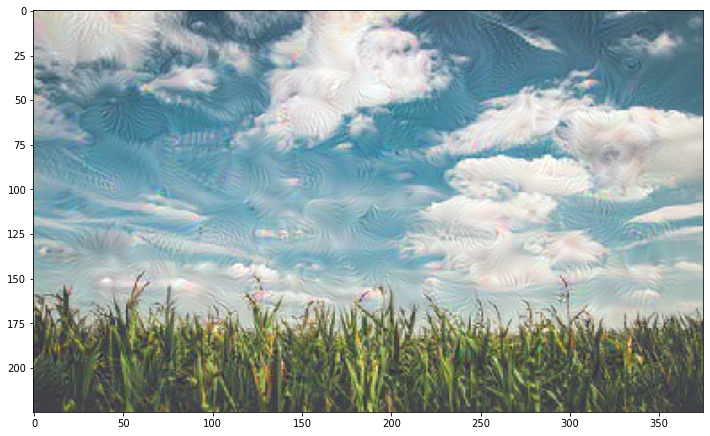

Epoch 1200, loss 1.523162841796875


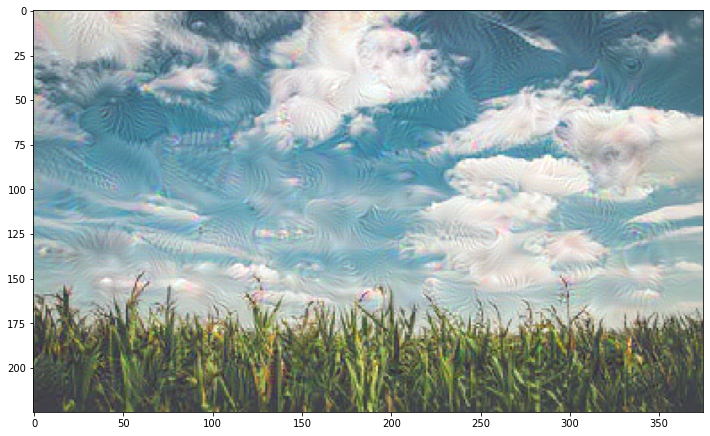

Epoch 1400, loss 1.57943856716156


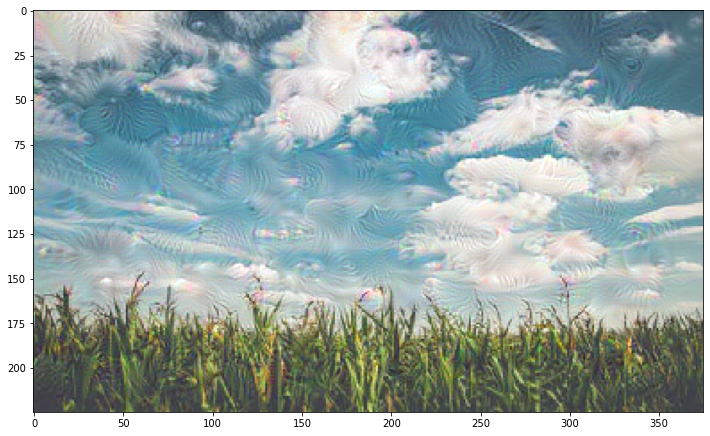

Epoch 1600, loss 1.6276543140411377


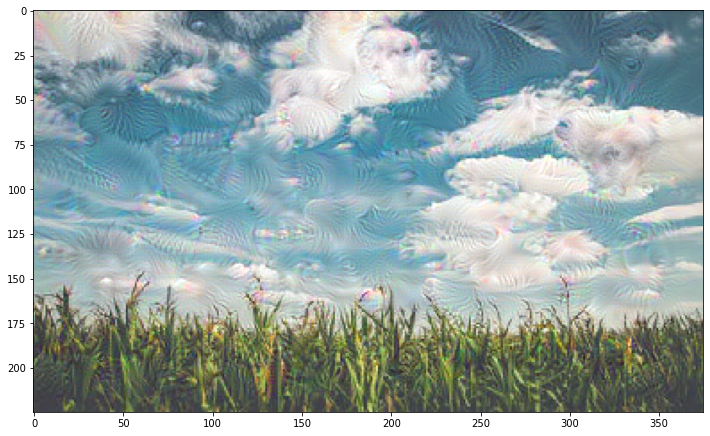

Epoch 1800, loss 1.670001745223999


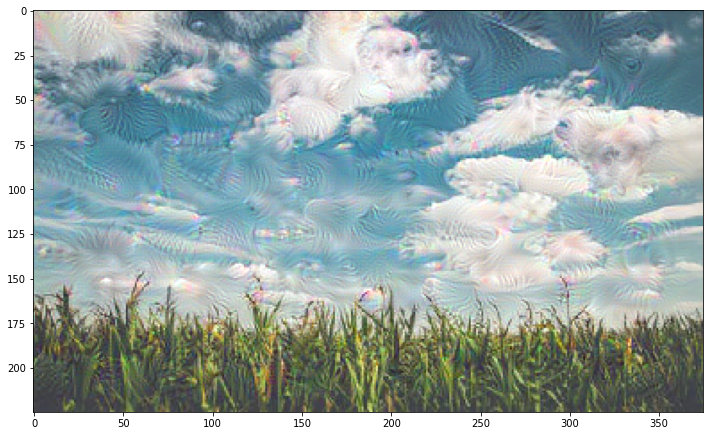

Epoch 2000, loss 1.7075235843658447


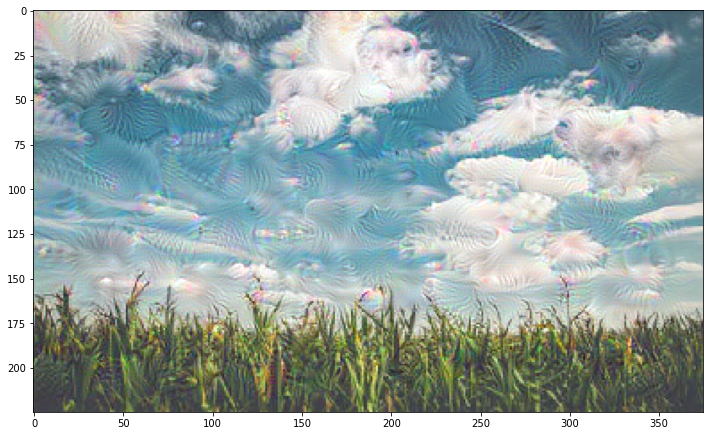

Epoch 2200, loss 1.7416073083877563


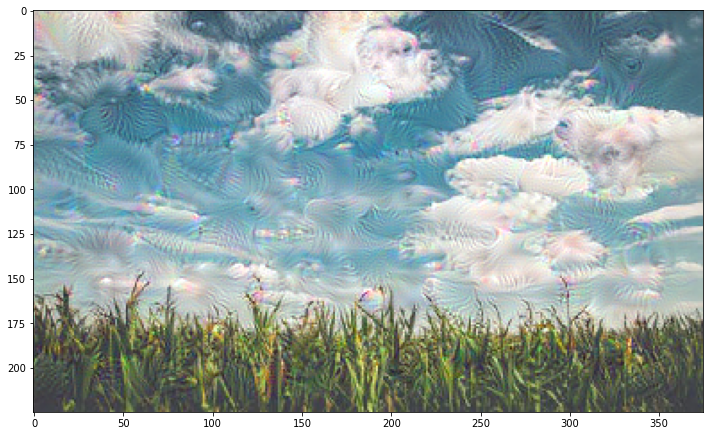

Epoch 2400, loss 1.773117184638977


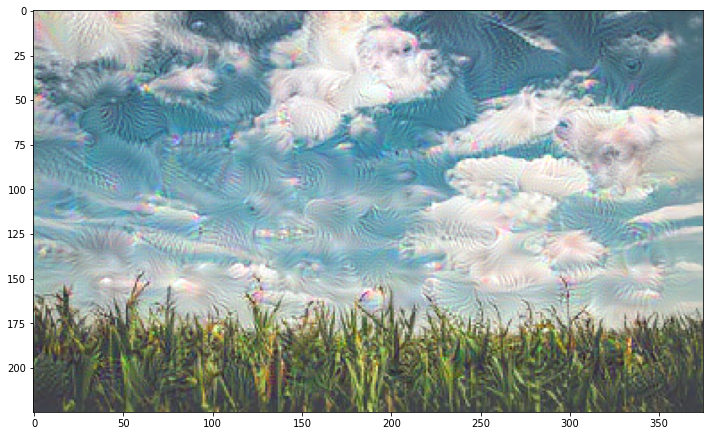

Epoch 2600, loss 1.8020826578140259


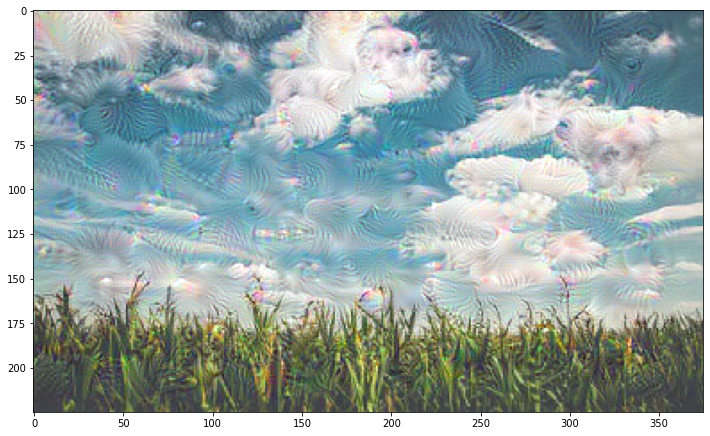

Epoch 2800, loss 1.8290600776672363


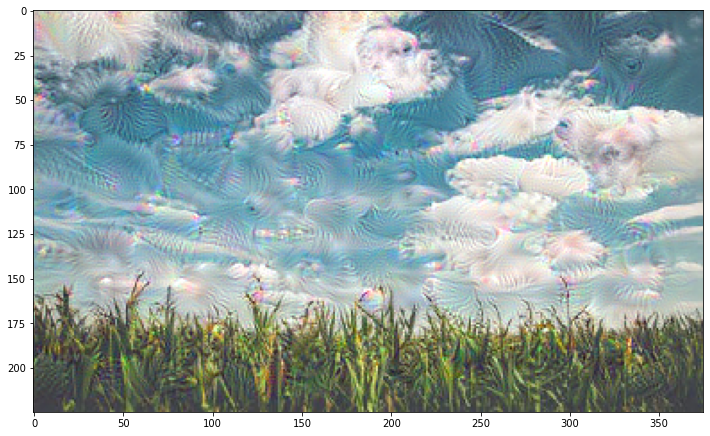

Epoch 3000, loss 1.854574203491211


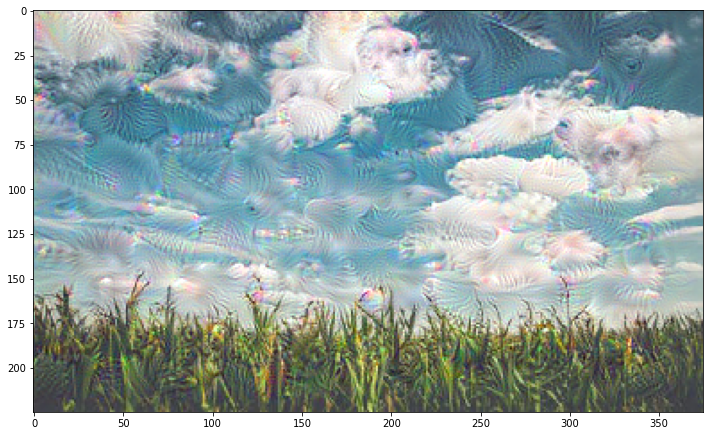

Epoch 3200, loss 1.878263235092163


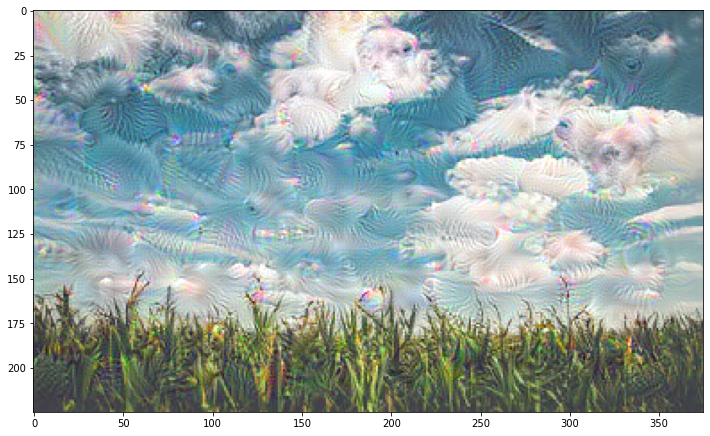

Epoch 3400, loss 1.900646686553955


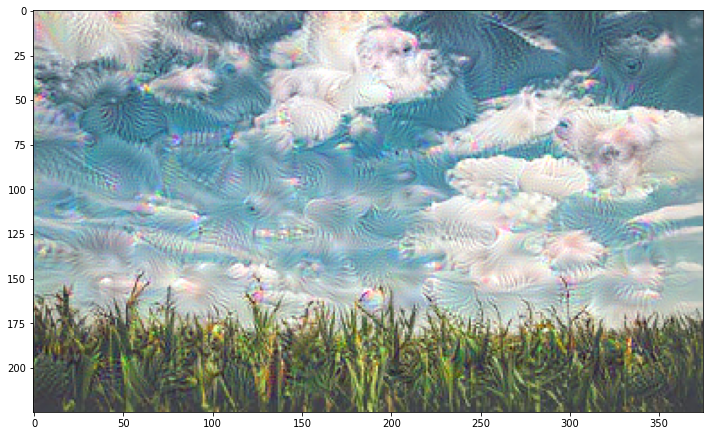

Epoch 3600, loss 1.9221255779266357


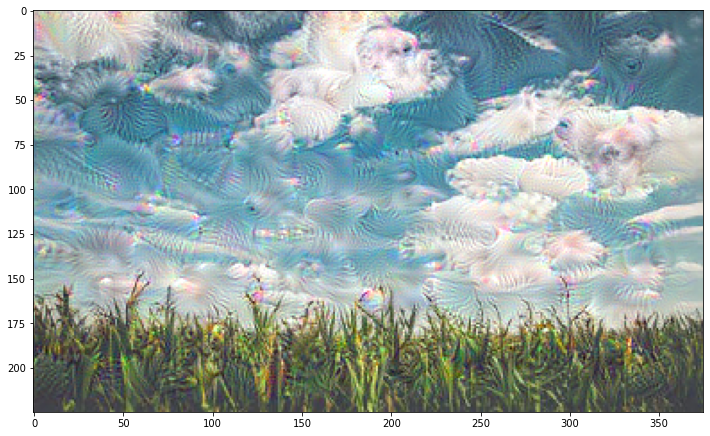

Epoch 3800, loss 1.942427396774292


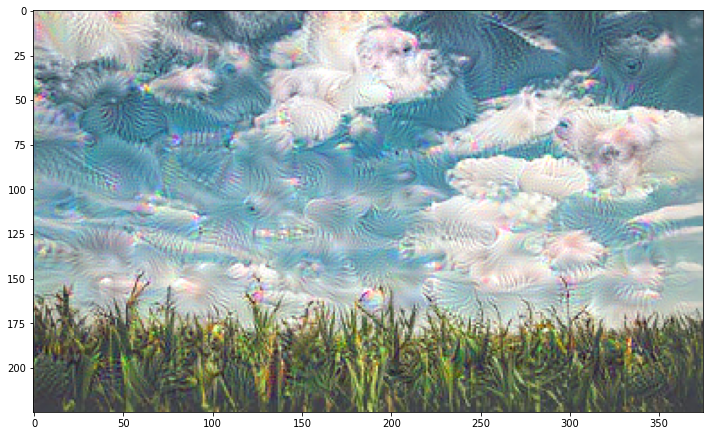

Epoch 4000, loss 1.9618232250213623


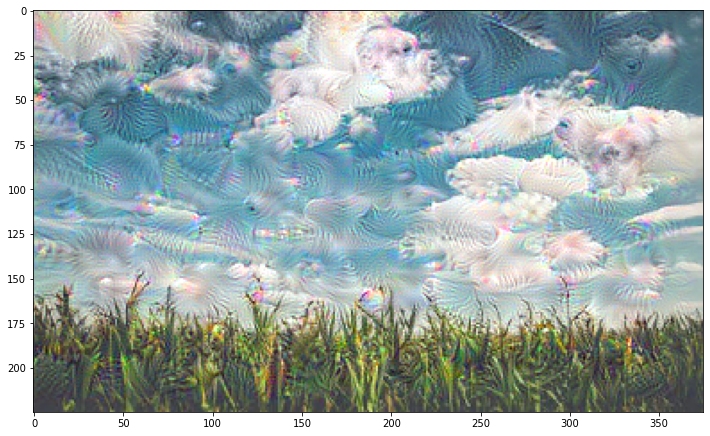

Epoch 4200, loss 1.9805891513824463


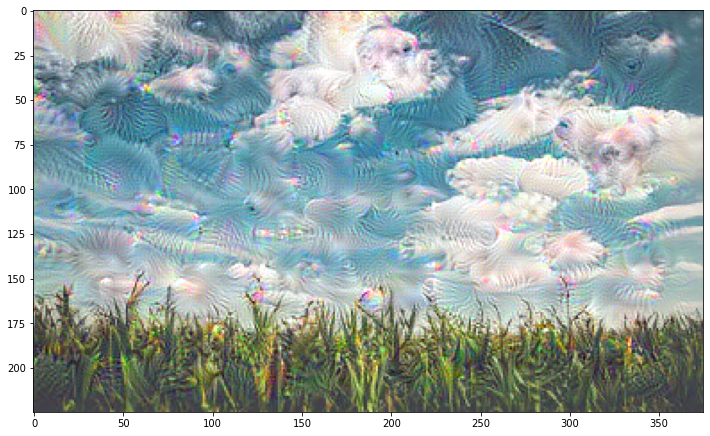

Epoch 4400, loss 1.998737096786499


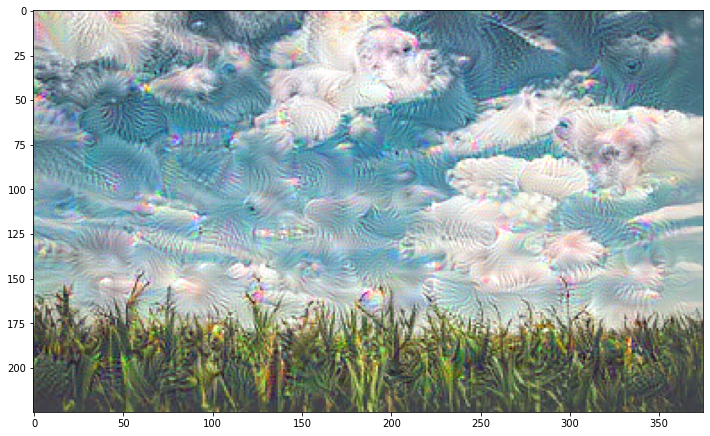

Epoch 4600, loss 2.016355276107788


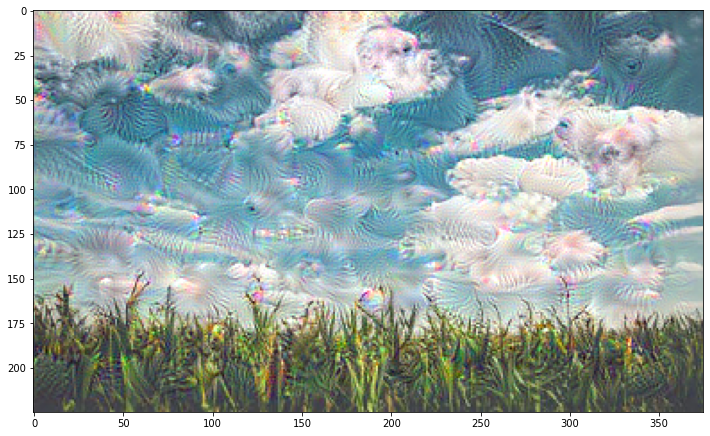

Epoch 4800, loss 2.033545970916748


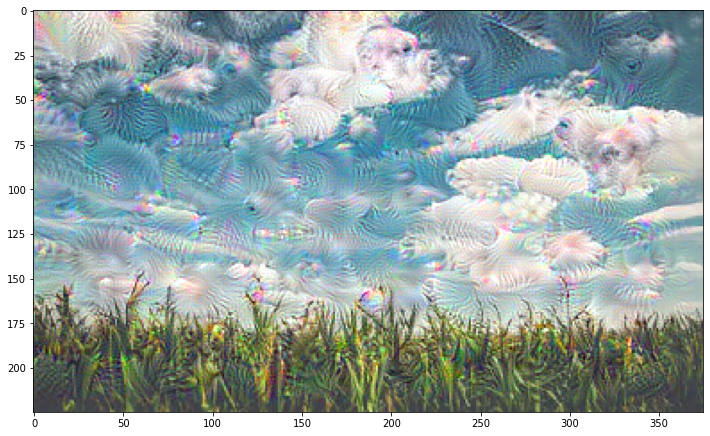

Epoch 5000, loss 2.049970865249634


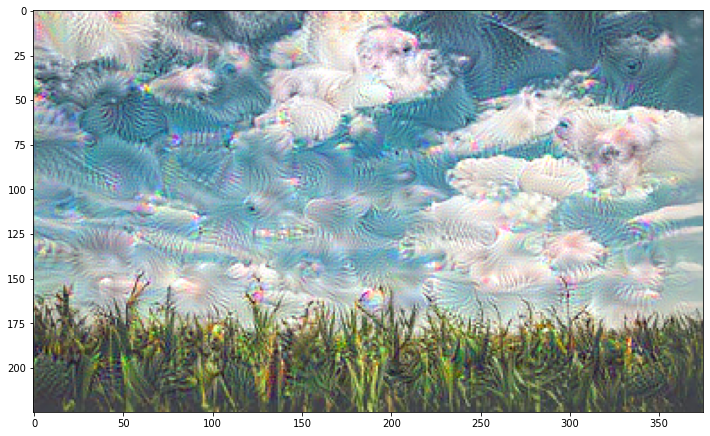

Epoch 5200, loss 2.065629243850708


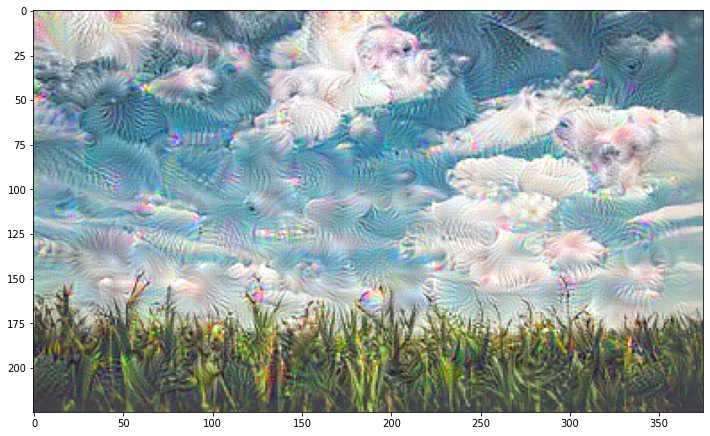

Epoch 5400, loss 2.0809593200683594


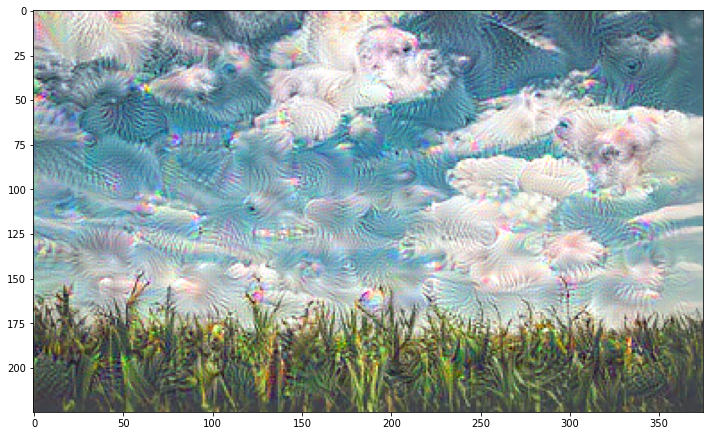

Epoch 5600, loss 2.0958969593048096


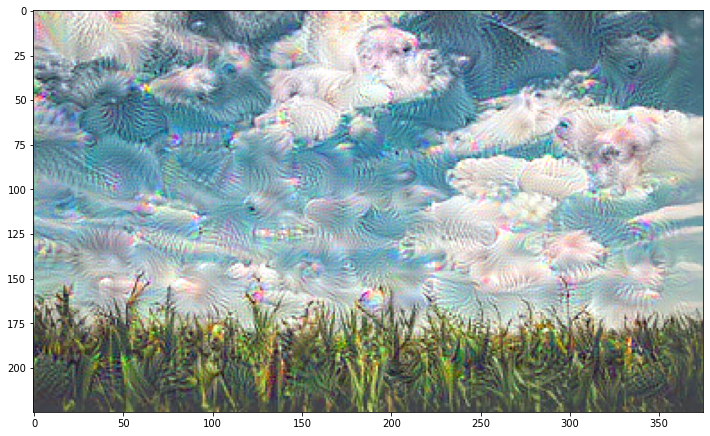

Epoch 5800, loss 2.1103641986846924


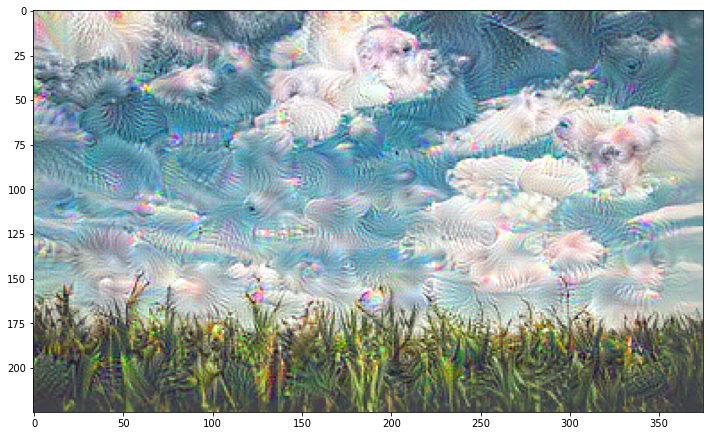

Epoch 6000, loss 2.1243503093719482


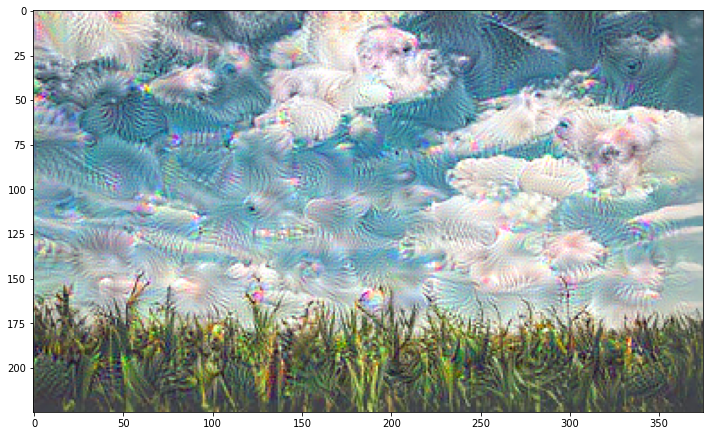

Epoch 6200, loss 2.1380248069763184


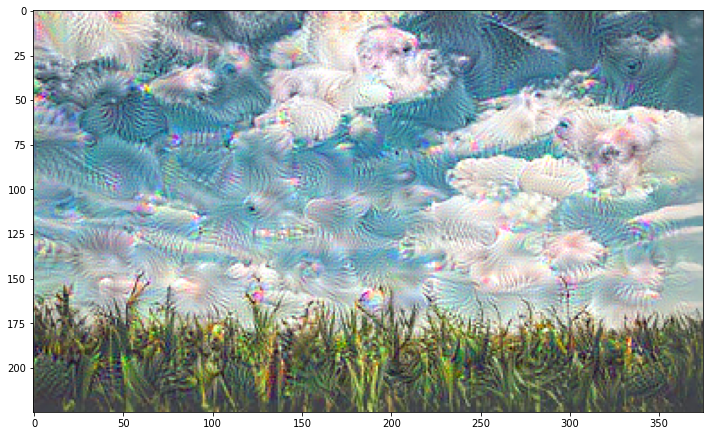

Epoch 6400, loss 2.1510934829711914


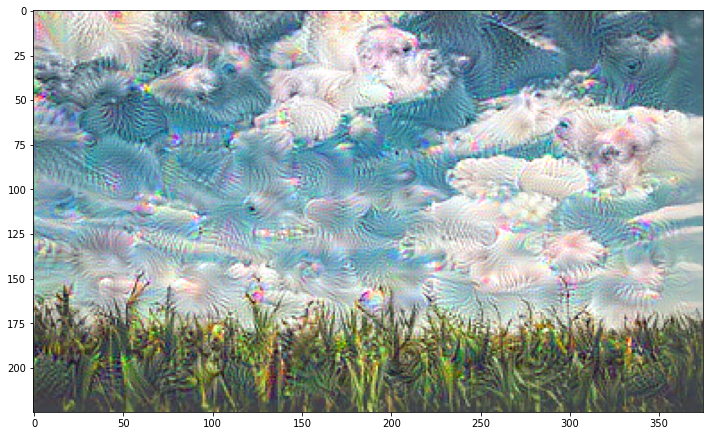

Epoch 6600, loss 2.1638145446777344


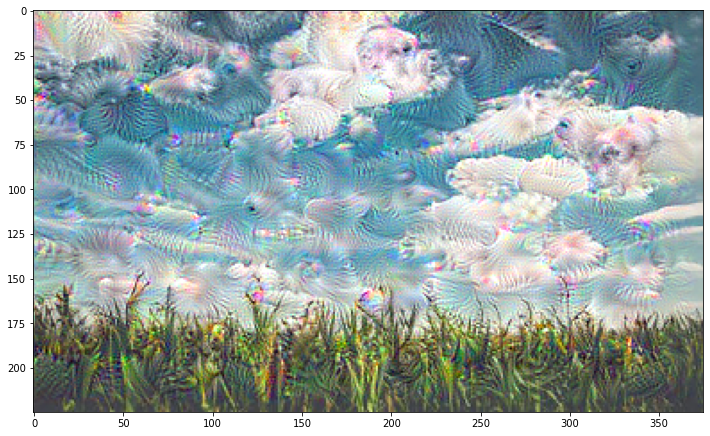

Epoch 6800, loss 2.1762640476226807


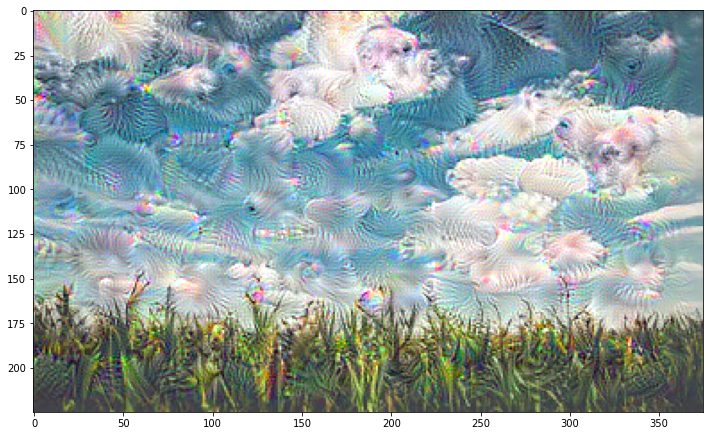

Epoch 7000, loss 2.188399076461792


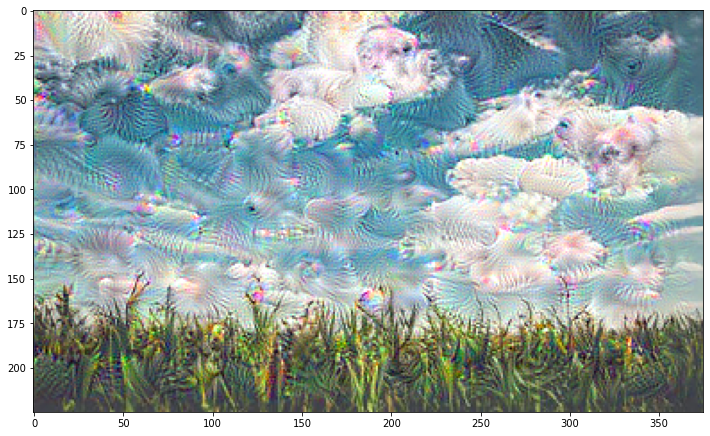

Epoch 7200, loss 2.200153350830078


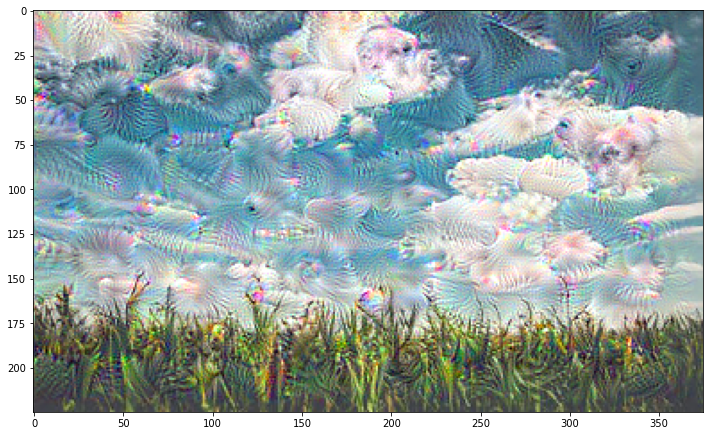

Epoch 7400, loss 2.2116613388061523


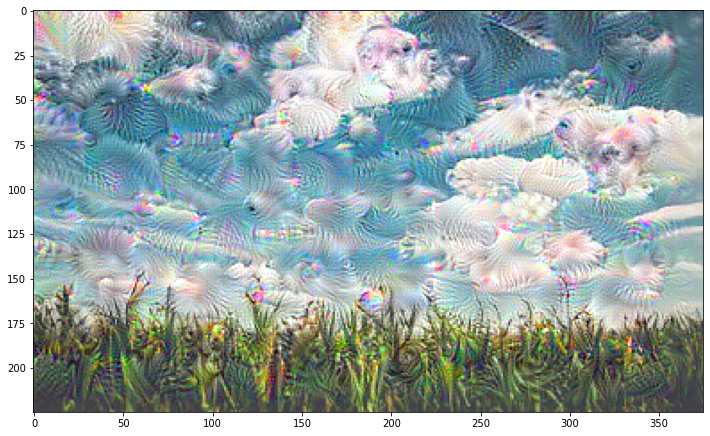

Epoch 7600, loss 2.2229299545288086


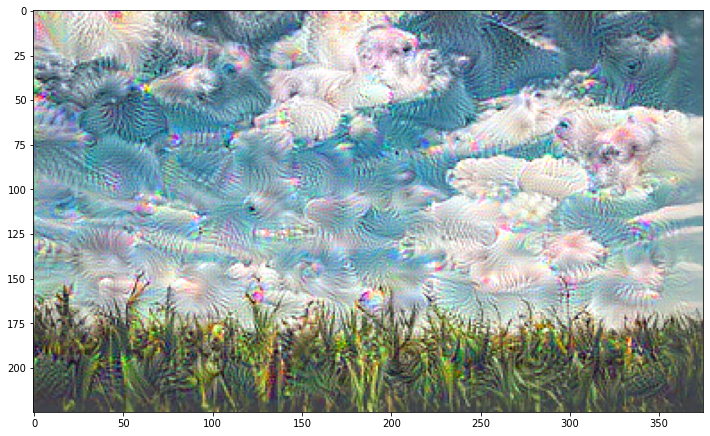

Epoch 7800, loss 2.234143018722534


In [ ]:
run_deep_dream(network = deep_dream_model, image = image, epochs = 8000, learning_rate = 0.0001)